## Plotly Tutorial

In [2]:
import pandas as pd
import numpy as np
import plotly as py
import plotly.express as px


### Basics

In [3]:
df = pd.DataFrame(np.random.randn(300, 3), columns = ["X", "Y", "Z"])
df.head()

,X,Y,Z
0,-0.177632,-1.017512,0.266164
1,-1.180116,-0.380924,-2.387547
2,-0.401007,0.322005,1.046414
3,-0.779518,-0.198680,0.122051
4,0.240506,0.296227,-0.775912


<Axes: >

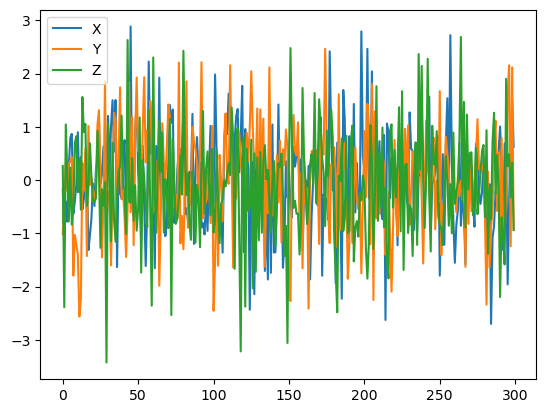

In [4]:
df.plot()
#this is done using matplotlib

* do the same with plotly. Can you see the difference?

In [5]:
fig = px.line(df)
fig.show()

* let's play with gapminder data. Which is the life expectancy trend in Europe in the most populated countries?
Questions
* can you fix the colormap issue like in the matplotlib example?

In [6]:
df = px.data.gapminder().query("continent == 'Europe' and pop > 2.e6")

#
df.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
16,Albania,Europe,1972,67.690,2263554,3313.422188,ALB,8
17,Albania,Europe,1977,68.930,2509048,3533.003910,ALB,8
18,Albania,Europe,1982,70.420,2780097,3630.880722,ALB,8
19,Albania,Europe,1987,72.000,3075321,3738.932735,ALB,8
20,Albania,Europe,1992,71.581,3326498,2497.437901,ALB,8


In [7]:
df = px.data.gapminder().query("continent == 'Europe' and pop > 2.e6")

fig = px.line(df, x="year", y="lifeExp", color='country',hover_data={'year':False})
fig.update_traces(mode="markers+lines", hovertemplate=None)
#fig.update_layout(hovermode="y")
#fig.update_layout(hovermode="x unified")
#
fig.show()

### Customized graphic objects

In [75]:
# Use included Google price data to make one plot
df_stocks = px.data.stocks()
px.line(df_stocks, x='date', y='GOOG', labels={'x':'Date', 'y':'Price'})



to perform basic stylling, assign the graph object to variable and update

In [76]:

df = px.data.gapminder().query("country == 'Italy'")

# Create a standard line plot
fig = px.line(df, x="year", y="gdpPercap", title="Customized Plotly Line Plot")
fig.show()
# Customize X-Axis (Range, Ticks, and Labels)
fig.update_xaxes(
    range=[1950, 2010],                  # Set axis range [min, max]
    tickfont=dict(size=14),              # Change tick font size
    title_font=dict(size=18)             # Change axis label font size
)

# Customize Y-Axis (Range, Ticks, and Labels)
fig.update_yaxes(
    range=[0, 40000],                # Set axis range [min, max]
    tickfont=dict(size=14),              # Change tick font size
    title_font=dict(size=18)             # Change axis label font size
)


In [77]:
# Use included Google price data to make one plot
df_stocks = px.data.stocks()
fig = px.line(df_stocks, x='date', y='GOOG', labels={'x':'Date', 'y':'Price'})


In [78]:
# Make multiple line plots
px.line(df_stocks, x='date', y=['GOOG','AAPL'], labels={'x':'Date', 'y':'Price'},
       title='Apple Vs. Google')

Using graph objects we can first create the figure istance, then add the parts

In [79]:
# Allows us to create graph objects for making more customized plots
import plotly.graph_objects as go


# Create a figure to which I'll add plots
fig = go.Figure()
# You can pull individual columns of data from the dataset and use markers or not
fig.add_trace(go.Scatter(x=df_stocks.date, y=df_stocks.AAPL, 
                        mode='lines', name='Apple'))
fig.add_trace(go.Scatter(x=df_stocks.date, y=df_stocks.AMZN, 
                        mode='lines+markers', name='Amazon'))
# You can create custom lines (Dashes : dash, dot, dashdot)
fig.add_trace(go.Scatter(x=df_stocks.date, y=df_stocks.GOOG, 
                        mode='lines+markers', name='Google',
                        line=dict(color='firebrick', width=2, dash='dashdot')))
# Further style the figure
fig.update_layout(title='Stock Price Data 2018 - 2019', xaxis_title='Date', yaxis_title='Price')

# Go crazy styling the figure
fig.update_layout(
    # Shows gray line without grid, styling fonts, linewidths and more
    xaxis=dict(
        showline=True,
        showgrid=False,
        showticklabels=True,
        linecolor='rgb(204, 204, 204)',
        linewidth=2,
        ticks='outside',
        tickfont=dict(
            family='Arial',
            size=12,
            color='rgb(82, 82, 82)',
        ),
    ),
    # Turn off everything on y axis
    yaxis=dict(
        showgrid=False,
        zeroline=False,
        showline=False,
        showticklabels=False,
    ),
    autosize=False,
    margin=dict(
        autoexpand=False,
        l=100,
        r=20,
        t=110,
    ),
    showlegend=False,
    plot_bgcolor='white'
)

### Bar Charts

In [80]:
# Get population change in Italy
df_it = px.data.gapminder().query("country == 'Italy'")
fig = px.bar(df_it, x='year', y='pop')

#styling
fig.update_layout(
    title_text="<b>title</b>",
    title_font_size=30
)

# fig.update_layout(
#     title=dict(text="<b>title</b>", font=dict(size=30))
# )

fig.update_xaxes(title_text="year", title_font=dict(size=20,color="red"))
# we can add annotations to the figure, which are text boxes that can be placed anywhere on the figure. We can also add arrows to point to specific data points.
fig.add_annotation(x=2007, y=60000000,
            text="maximum",
            showarrow=True,
            arrowhead=1)




In [12]:
import plotly.express as px

long_df = px.data.medals_long()
print(long_df)
fig = px.bar(long_df, x="nation", y="count", color="medal", title="Long-Form Input")
fig.show()

        nation   medal  count
0  South Korea    gold     24
1        China    gold     10
2       Canada    gold      9
3  South Korea  silver     13
4        China  silver     15
5       Canada  silver     12
6  South Korea  bronze     11
7        China  bronze      8
8       Canada  bronze     12


In [13]:
import plotly.express as px

wide_df = px.data.medals_wide()
print(wide_df)
fig = px.bar(wide_df, x="nation", y=["gold", "silver", "bronze"], title="Wide-Form Input")
fig.show()

        nation  gold  silver  bronze
0  South Korea    24      13      11
1        China    10      15       8
2       Canada     9      12      12


* Display pop data for countries in Europe in 2007 greater than 2000000

In [14]:

df_europe = px.data.gapminder().query("continent == 'Europe' and year == 2007 and pop > 2.e6")
fig = px.bar(df_europe, y='pop', x='country', text='pop', color='country')#,color_discrete_sequence=px.colors.qualitative.Light24)
# Put bar total value above bars with 2 values of precision
fig.update_traces(texttemplate='%{text:.2s}', textposition='outside')
# Set fontsize and uniformtext_mode='hide' says to hide the text if it won't fit
fig.update_layout(uniformtext_minsize=8)
# Rotate labels 45 degrees
fig.update_layout(xaxis_tickangle=-45)


### Scatter Plot

In [15]:
# Use included Iris data set
df_iris = px.data.iris()
# Create a scatter plot by defining x, y, different color for count of provided
# column, size based on supplied column and additional data to display on hover
px.scatter(df_iris, x="sepal_width", y="sepal_length", color="species",
                 size='petal_length', hover_data=['petal_width'])


### Pie Charts

In [16]:
# Create Pie chart of the largest nations in Europe
# Color maps here plotly.com/python/builtin-colorscales/
df_samer = px.data.gapminder().query("year == 2007").query("continent == 'Europe'")
px.pie(df_samer, values='pop', names='country', 
       title='Population of European continent', 
       color_discrete_sequence=px.colors.sequential.RdBu)


In [17]:

# Customize pie chart
colors = ['blue', 'green', 'black', 'purple', 'red', 'brown']
fig = go.Figure(data=[go.Pie(labels=['Water','Grass','Normal','Psychic', 'Fire', 'Ground'], 
                       values=[110,90,80,80,70,60])])
# Define hover info, text size, pull amount for each pie slice, and stroke
fig.update_traces(hoverinfo='label+percent', textfont_size=20,
                  textinfo='label+percent', pull=[0.1, 0, 0.2, 0, 0, 0],
                  marker=dict(colors=colors, line=dict(color='#FFFFFF', width=2)))

### heatmap (or image?)

In [104]:
vegetables = ["cucumber", "tomato", "lettuce", "asparagus", "potato", "wheat", "barley"]
farmers = ["Farmer Joe", "Upland Bros.", "Smith Gardening", "Agrifun", "Organiculture", "BioGoods Ltd.", "Cornylee Corp."]
harvest = np.array([[0.8, 2.4, 2.5, 3.9, 0.0, 4.0, 0.0],
                    [2.4, 0.0, 4.0, 1.0, 2.7, 0.0, 0.0],
                    [1.1, 2.4, 0.8, 4.3, 1.9, 4.4, 0.0],
                    [0.6, 0.0, 0.3, 0.0, 3.1, 0.0, 0.0],
                    [0.7, 1.7, 0.6, 2.6, 2.2, 6.2, 0.0],
                    [1.3, 1.2, 0.0, 0.0, 0.0, 3.2, 5.1],
                    [0.1, 2.0, 0.0, 1.4, 0.0, 1.9, 6.3]])

df = pd.DataFrame(harvest, index=farmers, columns=vegetables)

# 2. Build Heatmap
fig = px.imshow(
    df,
    text_auto=True,               # Automatically displays values inside cells
    color_continuous_scale="YlGn" # Yellow to Green color scale fit for crops
)

# 3. Apply customizations
fig.update_layout(
    title=dict(text="<b>Crop Harvest Tonnage</b>", font=dict(size=24)),
    xaxis_title="<b>Vegetables & Crops</b>",
    yaxis_title="<b>Farmers</b>"
)

fig.show()

### Density Heatmap

In [105]:
# Your data
vegetables = ["cucumber", "tomato", "lettuce", "asparagus", "potato", "wheat", "barley"]
farmers = ["Farmer Joe", "Upland Bros.", "Smith Gardening", "Agrifun", "Organiculture", "BioGoods Ltd.", "Cornylee Corp."]

harvest = np.array([[0.8, 2.4, 2.5, 3.9, 0.0, 4.0, 0.0],
                    [2.4, 0.0, 4.0, 1.0, 2.7, 0.0, 0.0],
                    [1.1, 2.4, 0.8, 4.3, 1.9, 4.4, 0.0],
                    [0.6, 0.0, 0.3, 0.0, 3.1, 0.0, 0.0],
                    [0.7, 1.7, 0.6, 2.6, 2.2, 6.2, 0.0],
                    [1.3, 1.2, 0.0, 0.0, 0.0, 3.2, 5.1],
                    [0.1, 2.0, 0.0, 1.4, 0.0, 1.9, 6.3]])

# Create the DataFrame
df = pd.DataFrame(harvest, index=farmers, columns=vegetables)
# Convert to long format
df_long = df.reset_index().melt(id_vars="index", var_name="vegetable", value_name="tonnage")
df_long = df_long.rename(columns={"index": "farmer"})
df_long.head()


# Build Heatmap
fig = px.density_heatmap(
    df_long,
    x="vegetable",
    y="farmer",
    z="tonnage",
    text_auto=True,
    color_continuous_scale="YlGn")

fig.update_layout(
    title=dict(text="<b>Crop Harvest Tonnage (Long Format)</b>", font=dict(size=24)),
    xaxis_title="<b>Vegetables & Crops</b>",
    yaxis_title="<b>Farmers</b>"
)

fig.show()


### 3D Scatter Plots

In [106]:
# Create a 3D scatter plot using flight data
fig = px.scatter_3d(flights, x='year', y='month', z='passengers', color='year',
                   opacity=0.7, width=800, height=400)
fig

### Scatter Matrix

In [107]:
# With a scatter matrix we can compare changes when comparing column data
fig = px.scatter_matrix(flights, color='month')
fig

## parallel coordinates

In [21]:
import plotly.express as px
df = px.data.iris()
fig = px.parallel_coordinates(df, color="species_id",
                              color_continuous_scale=px.colors.diverging.Tealrose,
                              color_continuous_midpoint=2)
fig.show()

### Polar Chart

In [22]:
# Polar charts display data radially 
# Let's plot wind data based on direction and frequency
# You can change size and auto-generate different symbols as well
df_wind = px.data.wind()
px.scatter_polar(df_wind, r="frequency", theta="direction", color="strength",
                size="frequency", symbol="strength")


In [23]:
# Data can also be plotted using lines radially
# A template makes the data easier to see
px.line_polar(df_wind, r="frequency", theta="direction", color="strength",
                line_close=True, template="plotly_dark", width=800, height=400)


### Facets

In [24]:
# You can create numerous subplots
df_tips = px.data.tips()
px.scatter(df_tips, x="total_bill", y="tip", color="smoker", facet_col="sex")


In [25]:

# We can line up data in rows and columns
px.histogram(df_tips, x="total_bill", y="tip", color="sex", facet_row="time", facet_col="day",
       category_orders={"day": ["Thur", "Fri", "Sat", "Sun"], "time": ["Lunch", "Dinner"]})

In [26]:


# This dataframe provides scores for different students based on the level
# of attention they could provide during testing
att_df = sns.load_dataset("attention")
fig = px.line(att_df, x='solutions', y='score', facet_col='subject',
             facet_col_wrap=5, title='Scores Based on Attention')
fig

### Animated Plots

In [27]:
# Create an animated plot that you can use to cycle through continent
# GDP & life expectancy changes
df_cnt = px.data.gapminder()
px.scatter(df_cnt, x="gdpPercap", y="lifeExp", animation_frame="year", 
           animation_group="country",
           size="pop", color="continent", hover_name="country",
           log_x=True, size_max=55, range_x=[100,100000], range_y=[25,90])

In [28]:

# Watch as bars chart population changes
px.bar(df_cnt, x="continent", y="pop", color="continent",
  animation_frame="year", animation_group="country", range_y=[0,4000000000])


webgl vs canvas

In [29]:
%%time
import plotly.express as px

import pandas as pd
import numpy as np
np.random.seed(1)

N = 100000

df = pd.DataFrame(dict(x=np.random.randn(N),
                       y=np.random.randn(N)))

fig = px.scatter(df, x="x", y="y")

fig.update_traces(marker_line=dict(width=1, color='DarkSlateGray'))

fig.show()

CPU times: total: 62.5 ms
Wall time: 64.5 ms


In [30]:
import plotly.graph_objects as go

import numpy as np

N = 100000

# Create figure
fig = go.Figure()

fig.add_trace(
    go.Scattergl(
        x = np.random.randn(N),
        y = np.random.randn(N),
        mode = 'markers',
        marker = dict(
            line = dict(
                width = 1,
                color = 'DarkSlateGrey')
        )
    )
)

fig.show()